In [2]:
!pip install -q -U datasets transformers accelerate scikit-learn seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 114.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 124.2 MB/s eta 0:00:00


In [1]:
!pip install -q datasets

from datasets import load_dataset

amazon = load_dataset("fancyzhx/amazon_polarity")

print(amazon)
print(amazon["train"][0])

amazon_polarity/train-00000-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  260MB            

amazon_polarity/train-00000-of-00004.par(…): downloading bytes:           |  0.00B            

amazon_polarity/train-00001-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  258MB            

amazon_polarity/train-00001-of-00004.par(…): downloading bytes:           |  0.00B            

amazon_polarity/train-00002-of-00004.par(…): reconstructing file:   0%|          |  0.00B /  255MB            

...

amazon_polarity/test-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  117MB            

amazon_polarity/test-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3600000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'title', 'content'],
        num_rows: 3600000
    })
    test: Dataset({
        features: ['label', 'title', 'content'],
        num_rows: 400000
    })
})
{'label': 1, 'title': 'Stuning even for the non-gamer', 'content': 'This sound track was beautiful! It paints the senery in your mind so well I would recomend it even to people who hate vid. game music! I have played the game Chrono Cross but out of all of the games I have ever played it has the best music! It backs away from crude keyboarding and takes a fresher step with grate guitars and soulful orchestras. It would impress anyone who cares to listen! ^_^'}


In [5]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [7]:
from datasets import load_dataset

amazon = load_dataset("fancyzhx/amazon_polarity")

print(amazon)

DatasetDict({
    train: Dataset({
        features: ['label', 'title', 'content'],
        num_rows: 3600000
    })
    test: Dataset({
        features: ['label', 'title', 'content'],
        num_rows: 400000
    })
})


In [9]:
# Inspect the Amazon Polarity dataset

print("Train example:")
print(amazon["train"][0])

print("\nTest example:")
print(amazon["test"][0])

print("\nLabel distribution:")
print(amazon["train"].features["label"])

Train example:
{'label': 1, 'title': 'Stuning even for the non-gamer', 'content': 'This sound track was beautiful! It paints the senery in your mind so well I would recomend it even to people who hate vid. game music! I have played the game Chrono Cross but out of all of the games I have ever played it has the best music! It backs away from crude keyboarding and takes a fresher step with grate guitars and soulful orchestras. It would impress anyone who cares to listen! ^_^'}

Test example:
{'label': 1, 'title': 'Great CD', 'content': 'My lovely Pat has one of the GREAT voices of her generation. I have listened to this CD for YEARS and I still LOVE IT. When I\'m in a good mood it makes me feel better. A bad mood just evaporates like sugar in the rain. This CD just oozes LIFE. Vocals are jusat STUUNNING and lyrics just kill. One of life\'s hidden gems. This is a desert isle CD in my book. Why she never made it big is just beyond me. Everytime I play this, no matter black, white, young, o

In [11]:
from datasets import DatasetDict

# Number of examples per class
N_PER_CLASS = 50000

train_data = amazon["train"]

negative_train = train_data.filter(
    lambda x: x["label"] == 0
).shuffle(seed=42).select(range(N_PER_CLASS))

positive_train = train_data.filter(
    lambda x: x["label"] == 1
).shuffle(seed=42).select(range(N_PER_CLASS))

print("Negative:", len(negative_train))
print("Positive:", len(positive_train))

Filter:   0%|          | 0/3600000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3600000 [00:00<?, ? examples/s]

Negative: 50000
Positive: 50000


In [12]:
from datasets import concatenate_datasets

train_subset = concatenate_datasets([
    negative_train,
    positive_train
]).shuffle(seed=42)

print(train_subset)

Dataset({
    features: ['label', 'title', 'content'],
    num_rows: 100000
})


In [13]:
split = train_subset.train_test_split(
    test_size=0.10,
    seed=42,
    stratify_by_column="label"
)

train_dataset = split["train"]
validation_dataset = split["test"]

print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))

Train: 90000
Validation: 10000


In [14]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

In [15]:
def tokenize_function(examples):

    texts = [
        f"{title}. {content}"
        for title, content
        in zip(
            examples["title"],
            examples["content"]
        )
    ]

    return tokenizer(
        texts,
        truncation=True,
        padding="max_length",
        max_length=128
    )

In [16]:
tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["title", "content"]
)

tokenized_validation = validation_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["title", "content"]
)

Map:   0%|          | 0/90000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [17]:
from transformers import AutoModelForSequenceClassification

id2label = {
    0: "negative",
    1: "positive"
}

label2id = {
    "negative": 0,
    "positive": 1
}

sentiment_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [18]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted"
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [19]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./amazon_distilbert",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    num_train_epochs=2,

    weight_decay=0.01,

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    logging_steps=100,

    report_to="none",

    fp16=torch.cuda.is_available()
)

In [20]:
from transformers import Trainer

trainer = Trainer(
    model=sentiment_model,
    args=training_args,

    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,

    compute_metrics=compute_metrics
)

In [21]:
train_output = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.134612,0.210301,0.936300,0.937973,0.936300,0.936239
2,0.097225,0.196280,0.946100,0.946113,0.946100,0.946100


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [22]:
validation_results = trainer.evaluate(
    tokenized_validation
)

for key, value in validation_results.items():
    print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.097225,0.196280,2,0.946100,0.946113,0.946100,0.946100


eval_loss: 0.1962796151638031
eval_accuracy: 0.9461
eval_precision: 0.9461130086553324
eval_recall: 0.9461
eval_f1: 0.9460996070661355


In [23]:
test_subset = amazon["test"].shuffle(
    seed=42
).select(range(20000))

print(test_subset)

Dataset({
    features: ['label', 'title', 'content'],
    num_rows: 20000
})


In [24]:
tokenized_test = test_subset.map(
    tokenize_function,
    batched=True,
    remove_columns=["title", "content"]
)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

In [25]:
test_results = trainer.evaluate(
    tokenized_test
)

print("Amazon Test Results")

for key, value in test_results.items():
    print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.097225,0.186114,2,0.952150,0.952156,0.952150,0.952150


Amazon Test Results
eval_loss: 0.18611443042755127
eval_accuracy: 0.95215
eval_precision: 0.9521555397449943
eval_recall: 0.95215
eval_f1: 0.9521501776440243


In [26]:
from sklearn.metrics import classification_report

predictions = trainer.predict(
    tokenized_test
)

y_pred = np.argmax(
    predictions.predictions,
    axis=-1
)

y_true = predictions.label_ids

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "negative",
            "positive"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

    negative     0.9505    0.9536    0.9520      9961
    positive     0.9538    0.9507    0.9523     10039

    accuracy                         0.9522     20000
   macro avg     0.9521    0.9522    0.9521     20000
weighted avg     0.9522    0.9522    0.9522     20000



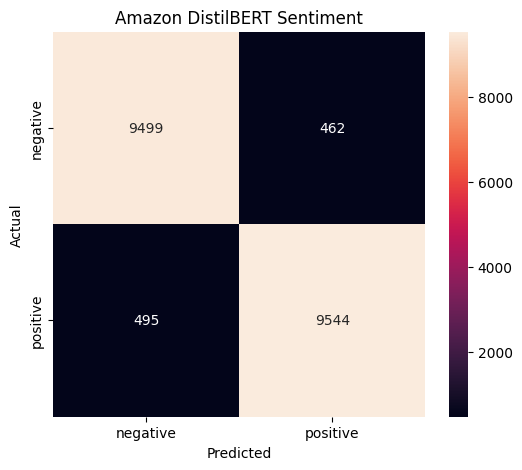

In [27]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["negative", "positive"],
    yticklabels=["negative", "positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Amazon DistilBERT Sentiment")

plt.show()

In [28]:
test_sentences = [
    "I am very happy with my order, thank you!",
    "My order still hasn't arrived and I am really angry.",
    "This is absolutely terrible, I want my money back.",
    "The delivery was fast and everything arrived perfectly.",
    "I have been waiting for my refund for two weeks.",
    "The product arrived damaged and I am very disappointed."
]

In [29]:
inputs = tokenizer(
    test_sentences,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

inputs = {
    key: value.to(trainer.model.device)
    for key, value in inputs.items()
}

with torch.no_grad():

    outputs = trainer.model(
        **inputs
    )

    probabilities = torch.softmax(
        outputs.logits,
        dim=-1
    )

    predictions = torch.argmax(
        probabilities,
        dim=-1
    )

for text, pred, probs in zip(
    test_sentences,
    predictions.cpu().numpy(),
    probabilities.cpu().numpy()
):

    print("Text:", text)
    print("Sentiment:", id2label[int(pred)])
    print(
        "Confidence:",
        round(float(probs[pred]), 4)
    )
    print("-" * 80)

Text: I am very happy with my order, thank you!
Sentiment: positive
Confidence: 0.9963
--------------------------------------------------------------------------------
Text: My order still hasn't arrived and I am really angry.
Sentiment: negative
Confidence: 0.9908
--------------------------------------------------------------------------------
Text: This is absolutely terrible, I want my money back.
Sentiment: negative
Confidence: 0.9995
--------------------------------------------------------------------------------
Text: The delivery was fast and everything arrived perfectly.
Sentiment: positive
Confidence: 0.9978
--------------------------------------------------------------------------------
Text: I have been waiting for my refund for two weeks.
Sentiment: negative
Confidence: 0.9727
--------------------------------------------------------------------------------
Text: The product arrived damaged and I am very disappointed.
Sentiment: negative
Confidence: 0.9992
------------------

In [30]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [31]:
import os

sentiment_path = "/content/drive/MyDrive/FogProject/Sentiment_Classification/amazon_distilbert"

os.makedirs(sentiment_path, exist_ok=True)

# Save model
trainer.model.save_pretrained(sentiment_path)

# Save tokenizer
tokenizer.save_pretrained(sentiment_path)

print("Model saved successfully!")
print("Path:", sentiment_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!
Path: /content/drive/MyDrive/FogProject/Sentiment_Classification/amazon_distilbert


In [32]:
import os

for file in os.listdir(sentiment_path):
    print(file)

config.json
model.safetensors
tokenizer_config.json
tokenizer.json


In [33]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

saved_path = "/content/drive/MyDrive/FogProject/Sentiment_Classification/amazon_distilbert"

tokenizer_test = AutoTokenizer.from_pretrained(saved_path)
model_test = AutoModelForSequenceClassification.from_pretrained(saved_path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_test.to(device)
model_test.eval()

text = "My order arrived damaged and I am very disappointed."

inputs = tokenizer_test(
    text,
    return_tensors="pt",
    truncation=True,
    max_length=128
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model_test(**inputs)
    probabilities = torch.softmax(outputs.logits, dim=-1)
    prediction = torch.argmax(probabilities, dim=-1).item()

print("Text:", text)
print("Prediction:", model_test.config.id2label[prediction])
print("Confidence:", round(probabilities[0][prediction].item(), 4))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Text: My order arrived damaged and I am very disappointed.
Prediction: negative
Confidence: 0.9985
